# Simulación de brecha de competencias digitales — UADE vs. EE.UU. (con embeddings)

Notebook de trabajo del proyecto **Skill Gap UADE–EE.UU.** Implementa el enfoque metodológico acordado:

1. **Relevamiento** de planes de estudio desde URLs (o desde planes semilla ya cargados).
2. **Clasificación por capas**: `core` (obligatoria), `major_elective` (electiva de la disciplina), `gen_ed` (educación general), `free` (libre), `excluir`.
3. **Mapeo híbrido (palabras clave + embeddings semánticos)** de cada materia a las 17 *knowledge areas* de **ACM/IEEE/AAAI CS2023** (dimensión técnica) y a las 21 competencias de **DigComp 3.0** (dimensión transversal), con nivel 1–4 y relevancia 0–1. Revisable a mano.
4. **Cobertura garantizada** (solo `core`) y **cobertura ofrecida** (`core` + `major_elective`).
5. **Índices**: CCI, profundidad, brecha por área *G(c)*, **DSGI** ponderado por perfil de carrera, subíndices (técnico, transversal, IA, flexibilidad) y ventajas diferenciales; percentiles, z-scores e IC por bootstrap.
6. **Redes complejas**: RCA, proximidad, densidad, centralidad y mapa de priorización (centralidad × densidad).
7. **Exportación** a Excel.

### Cómo usarlo
1. Agregá universidades en la lista `PROGRAMAS` (celda de configuración): un `id`, nombre, URL y rol (`focal` para UADE, `benchmark` para las de EE.UU.).
2. Corré todo (*Run All*). Para cada programa nuevo, el notebook descarga la página y genera `datos/planes/<id>.csv` con las materias detectadas.
3. **Revisá ese CSV** (capa, créditos, nombres) y volvé a correr. El notebook **nunca sobrescribe** un CSV existente, así que tus correcciones se conservan.
4. Revisá `datos/mapeo/<id>.csv`. Las filas que marques con `fuente = manual` se respetan en cada corrida.

> **Requisitos:** `pip install pandas numpy requests beautifulsoup4 networkx matplotlib openpyxl scikit-learn sentence-transformers`
>
> La primera corrida descarga el modelo `paraphrase-multilingual-MiniLM-L12-v2` (unos 470 MB) y después queda en caché. Sin conexión, el notebook usa un respaldo TF-IDF que solo sirve para probar el flujo.
>
> **Mejora clave:** sumá una columna `contenidos` en `datos/planes/<id>.csv` con los contenidos mínimos de cada materia. El embedding la usa junto con el nombre.
>
> **Advertencia metodológica:** el mapeo automático (palabras clave y embeddings) usa los **nombres** de las materias y, si existen, sus contenidos. Es un punto de partida para la validación por jueces expertos (sección 8 del documento metodológico), no un resultado final.

In [43]:
import re, json, unicodedata, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_rows", 200, "display.max_columns", 50, "display.width", 160)

## 1. Configuración

In [44]:
# ----------------------------------------------------------------------------
# PROGRAMAS A COMPARAR — agregá filas acá.
#   id        : identificador corto, sin espacios (se usa como nombre de archivo)
#   nombre    : nombre legible
#   url       : página del plan de estudios / catálogo
#   rol       : 'focal' (UADE) o 'benchmark' (universidades de EE.UU.)
#   seed      : opcional; nombre de un plan semilla ya cargado en el notebook
# ----------------------------------------------------------------------------
PROGRAMAS = [
    dict(id="uade_iacd", nombre="UADE – Lic. en IA y Ciencia de Datos", rol="focal",
         url="https://www.uade.edu.ar/facultad-de-ingenieria-y-ciencias-exactas/licenciatura-en-inteligencia-artificial-y-ciencia-de-datos/plan-de-estudios/",
         seed="uade_iacd"),
    dict(id="indiana_it_cs_ai", nombre="Computer Science - AI Concentration, B.A.", rol="benchmark",
         url="https://catalog.indianatech.edu/preview_program.php?catoid=22&poid=5972&_gl=1*th3ewr*_ga*MzE2NjMyNDQ1LjE3OTQyNzcwNzg.*_ga_RLG9QG9003*czE3OTQyNzcwNzgkbzEkZzEkdDE3OTQyNzcwODkkajQ5JGwwJGgw",
         seed="indiana_it_cs_ai"),
    dict(id="iit_bs_ai", nombre="Illinois Tech – BS Artificial Intelligence", rol="benchmark",
         url="https://catalog.iit.edu/undergraduate/colleges/computing/computer-science/bs-artificial-intelligence/",
         seed="iit_bs_ai"),
    # dict(id="otra_univ", nombre="Universidad X – BS Data Science", rol="benchmark",
    #      url="https://..."),
]

PERFIL = "ia_datos"          # perfil de pesos para el DSGI técnico (ver sección 2)
DESCARGAR = True             # False = no intenta descargar; usa solo CSV existentes y semillas
CREDITOS_DEFAULT = 3.0       # créditos asumidos cuando el plan no los informa (p. ej., UADE)
N_BOOTSTRAP = 2000
SEMILLA_ALEATORIA = 42

# Mapeo materia → competencia
MODO_MAPEO = "hibrido"       # "hibrido" | "embeddings" | "keywords"
MODELO_EMB = "paraphrase-multilingual-MiniLM-L12-v2"   # modelo multilingüe de sentence-transformers
UMBRAL_EMB = "auto"          # "auto" o (primario, secundario), p. ej. (0.50, 0.40)
TOPK_EMB = 3                 # máximo de competencias por materia y por marco vía embeddings
PERMITIR_RESPALDO_TFIDF = False  # True solo para probar el flujo sin el modelo (resultados no válidos)

DATOS = Path("datos")
(DATOS / "planes").mkdir(parents=True, exist_ok=True)
(DATOS / "mapeo").mkdir(parents=True, exist_ok=True)
(DATOS / "resultados").mkdir(parents=True, exist_ok=True)

FOCAL = [p["id"] for p in PROGRAMAS if p["rol"] == "focal"][0]
BENCH = [p["id"] for p in PROGRAMAS if p["rol"] == "benchmark"]
NOMBRE = {p["id"]: p["nombre"] for p in PROGRAMAS}
print("Focal:", FOCAL, "| Benchmark:", BENCH)

Focal: uade_iacd | Benchmark: ['indiana_it_cs_ai', 'iit_bs_ai']


## 2. Marcos de referencia

- **CS2023**: 17 knowledge areas. Las palabras clave están en español e inglés; `prim` = relevancia 1,0 y `sec` = relevancia 0,5.
- **DigComp 3.0**: 21 competencias. El mapeo por nombre de materia es más débil para lo transversal; conviene reforzarlo con los programas de las materias.
- **Perfiles de pesos** *w(c)* por carrera. Se normalizan para que sumen 1. El perfil `ia_datos` es el que se usó en la simulación; ajustalo con el panel de expertos o con la demanda laboral.

In [45]:
CS2023 = {
 "AI":  dict(nombre="Inteligencia artificial",
             prim=["artificial intelligence","inteligencia artificial","machine learning","aprendizaje automatico",
                   "deep learning","redes neuronales","neural","natural language","lenguaje natural","language understanding",
                   "nlp","reinforcement","refuerzo","generativ","modelos de lenguaje","llm","statistical learning",
                   "probabilistic graphical","data mining","mineria de datos","sistemas autonomos","<ai>","<ia>"],
             sec=["vision artificial","computer vision","social media mining","robotic","robotica","cognitive science",
                  "learning theory","information retrieval","multimedia"]),
 "AL":  dict(nombre="Algoritmos y fundamentos",
             prim=["algorithm","algoritm","data structures","estructuras de datos","theoretical computer science",
                   "teoria de la computacion","computabilidad","automatas"],
             sec=["discrete","discreta","pensamiento computacional","logic in computer science"]),
 "AR":  dict(nombre="Arquitectura y organización",
             prim=["computer organization","assembly","digital design","digital hardware","arquitectura de computadoras",
                   "organizacion de computadoras","hardware"],
             sec=[]),
 "DM":  dict(nombre="Gestión de datos",
             prim=["database","bases de datos","base de datos","data management","gestion de datos","sql"],
             sec=["information systems","data science","ciencia de datos","analitica","analytics","canalizacion",
                  "pipeline","data mining","mineria de datos","big data"]),
 "FPL": dict(nombre="Lenguajes de programación",
             prim=["programming languages","lenguajes de programacion","programming paradigms","paradigmas",
                   "translators","compilador","compiler"],
             sec=["object-oriented","object oriented","orientacion a objetos","orientada a objetos"]),
 "GIT": dict(nombre="Gráficos y técnicas interactivas",
             prim=["graphics","grafica","multimedia","visualization","visualizacion"],
             sec=["vision artificial","computer vision","generativa visual","presentacion y comunicacion",
                  "sistemas de informacion geografic","geographic"]),
 "HCI": dict(nombre="Interacción humano-computadora",
             prim=["human-computer","human computer","interaccion humano","user experience","usability","usabilidad"],
             sec=["cognitive science","<ux>"]),
 "MSF": dict(nombre="Fundamentos matemáticos y estadísticos",
             prim=["calculus","calculo","algebra","statistic","estadistic","probabilit","inferencia","estimacion",
                   "discrete math","discrete structures","matematica discreta","regression","stochastic",
                   "computational mathematics","design and analysis of experiments","mathematical model","analisis matematico"],
             sec=["discrete","discreta","logic"]),
 "NC":  dict(nombre="Redes y comunicación",
             prim=["computer networks","networking","redes de computadoras","redes de datos","comunicacion de datos",
                   "internet","teleinformatica"],
             sec=[]),
 "OS":  dict(nombre="Sistemas operativos",
             prim=["operating systems","sistemas operativos"],
             sec=["systems programming"]),
 "PDC": dict(nombre="Computación paralela y distribuida",
             prim=["parallel","paralel","distributed","distribuid","cloud","nube"],
             sec=["big data"]),
 "SDF": dict(nombre="Fundamentos de desarrollo de software",
             prim=["programming","programacion","python","java","introduction to computer science",
                   "pensamiento computacional","object-oriented programming"],
             sec=["data structures"]),
 "SE":  dict(nombre="Ingeniería de software",
             prim=["software engineering","ingenieria de software","capstone","proyecto final","ingenieria de requerimientos"],
             sec=["projects","proyectos","interprofessional","seminario integrador"]),
 "SEC": dict(nombre="Seguridad",
             prim=["security","seguridad","information assurance","cyber","ciberseguridad","cryptograph","criptograf"],
             sec=[]),
 "SEP": dict(nombre="Sociedad, ética y profesión",
             prim=["ethic","etica","society","sociedad","profession","profesion","legal","philosophy","bioethics",
                   "information age"],
             sec=["consultoria","gestion y evaluacion de proyectos"]),
 "SF":  dict(nombre="Fundamentos de sistemas",
             prim=["systems fundamentals","computer systems","sistemas de computacion"],
             sec=["operating systems","sistemas operativos","computer organization","systems programming"]),
 "SPD": dict(nombre="Desarrollo en plataformas especializadas",
             prim=["mobile","movil","web development","desarrollo web","embedded","embebid","game"],
             sec=["robotic","robotica","plataformas"]),
}

DIGCOMP = {
 "1.1": dict(nombre="Búsqueda y filtrado de información", prim=["information retrieval","recuperacion de informacion","search","busqueda"], sec=[]),
 "1.2": dict(nombre="Evaluación de información", prim=["critical thinking","pensamiento critico","misinformation","desinformacion"], sec=["research methods","metodologia de la investigacion"]),
 "1.3": dict(nombre="Gestión de información y datos", prim=["database","bases de datos","data management","analytics","analitica","ciencia de datos","data science"], sec=["statistic","estadistic","mining","mineria"]),
 "2.1": dict(nombre="Interacción con y a través de tecnologías", prim=["chatbot","conversational","language understanding","modelos de lenguaje","natural language","lenguaje natural"], sec=["communication","comunicacion"]),
 "2.2": dict(nombre="Compartir", prim=["presentacion y comunicacion","technical communication","comunicacion de resultados"], sec=["communication","comunicacion"]),
 "2.3": dict(nombre="Ciudadanía digital", prim=["society","sociedad","citizenship","ciudadania","information age","legal"], sec=["social science","ciencias sociales","humanities","humanidades"]),
 "2.4": dict(nombre="Colaboración", prim=["collaborat","colaborat","teamwork","trabajo en equipo","interprofessional"], sec=["capstone","proyecto final","projects","proyectos","seminario integrador"]),
 "2.5": dict(nombre="Comportamiento digital", prim=["netiquette","digital behavio","comportamiento digital"], sec=[]),
 "2.6": dict(nombre="Identidad digital", prim=["digital identity","identidad digital"], sec=[]),
 "3.1": dict(nombre="Desarrollo de contenido", prim=["content creation","creacion de contenido","multimedia","generativa visual","composition"], sec=["presentacion","marketing digital"]),
 "3.2": dict(nombre="Integración y reelaboración de contenido", prim=["generativ"], sec=[]),
 "3.3": dict(nombre="Derechos de autor y licencias", prim=["copyright","licencia","intellectual property","propiedad intelectual"], sec=["legal"]),
 "3.4": dict(nombre="Pensamiento computacional y programación", prim=["programming","programacion","pensamiento computacional","python","java","algorithm","algoritm"], sec=["data structures","estructuras de datos"]),
 "4.1": dict(nombre="Protección de dispositivos", prim=["security","seguridad","information assurance","cyber"], sec=["operating systems","sistemas operativos"]),
 "4.2": dict(nombre="Datos personales y privacidad", prim=["privacy","privacidad","data protection","proteccion de datos"], sec=["ethic","etica"]),
 "4.3": dict(nombre="Bienestar", prim=["wellbeing","well-being","bienestar"], sec=[]),
 "4.4": dict(nombre="Impacto ambiental", prim=["sustainab","sostenib","environment","ambiental"], sec=[]),
 "5.1": dict(nombre="Problemas técnicos", prim=["troubleshoot","systems programming","operating systems","sistemas operativos"], sec=["computer organization"]),
 "5.2": dict(nombre="Necesidades y respuestas tecnológicas", prim=["automation","automatizacion","consulting","consultoria","cloud","nube"], sec=["aplicaciones industriales","applications"]),
 "5.3": dict(nombre="Soluciones creativas", prim=["capstone","proyecto final","innovation","innovacion"], sec=["introduction to engineering","design","diseno"]),
 "5.4": dict(nombre="Necesidades de competencia digital", prim=["tendencias","trends","introduction to the profession"], sec=["seminario"]),
}

KA = list(CS2023)
DC = list(DIGCOMP)

# Perfiles de pesos w(c) para el DSGI técnico. 1 = relevante, 0 = fuera del perfil.
PERFILES = {
    "cs_completo": {k: 1 for k in KA},
    "ia_datos":    {k: (1 if k in ["AI","AL","DM","MSF","SDF","SE","SEC","SEP","PDC"] else 0) for k in KA},
    # Provisorio hasta definir el estándar de Bioinformática:
    "bioinformatica": {k: (1 if k in ["AI","AL","DM","MSF","SDF","SE","SEP","PDC"] else 0) for k in KA},
}
def pesos(perfil):
    w = pd.Series(PERFILES[perfil], dtype=float)
    return w / w.sum()

print(f"{len(KA)} áreas CS2023 · {len(DC)} competencias DigComp · perfil activo: {PERFIL}")
print("Áreas del perfil:", list(pesos(PERFIL)[lambda s: s > 0].index))

17 áreas CS2023 · 21 competencias DigComp · perfil activo: ia_datos
Áreas del perfil: ['AI', 'AL', 'DM', 'MSF', 'PDC', 'SDF', 'SE', 'SEC', 'SEP']


## 3. Planes semilla

Los tres planes de la simulación (UADE, ASU, Illinois Tech), relevados en noviembre de 2026. Se escriben a `datos/planes/` **solo si el CSV todavía no existe**.

**Reglas de codificación**
- Una opción comodín ("any 400-level CSE", "any CS 500-level") se marca `excluir`, porque haría infinita la cobertura ofrecida.
- Un slot obligatorio con menú (por ejemplo, el *AI Depth Course* de IIT) se codifica como fila `core` con el contenido mínimo común. Sus opciones van como `major_elective`.
- Con dos alternativas ("A o B"), se codifica la primera como `core` y la otra como `major_elective`.
- La columna `nivel` es opcional: si está vacía, el nivel se infiere del código o del año de cursada.

In [46]:
SEMILLAS = {}

_uade = [
 (1,"MARKETING"),(1,"PENSAMIENTO COMPUTACIONAL, ALGORITMIA Y PROGRAMACIÓN"),(1,"ÁLGEBRA"),(1,"INTRODUCCIÓN A LA CIENCIA DE DATOS"),
 (1,"ESTADÍSTICA GENERAL"),(1,"INTRODUCCIÓN A LA INTELIGENCIA ARTIFICIAL"),(1,"PYTHON PARA CIENCIA DE DATOS"),(1,"ÉTICA EN LA INTELIGENCIA ARTIFICIAL"),(1,"CÁLCULO"),
 (2,"INFERENCIA Y ESTIMACIÓN"),(2,"ORIENTACIÓN A OBJETOS CON PYTHON"),(2,"BASES DE DATOS RELACIONALES"),(2,"ANALÍTICAS DE MARKETING DIGITAL"),
 (2,"MACHINE LEARNING I"),(2,"MINERÍA DE DATOS"),(2,"PRESENTACIÓN Y COMUNICACIÓN DE RESULTADOS"),(2,"ANALÍTICAS PARA SISTEMAS DE INFORMACIÓN GEOGRÁFICOS"),
 (3,"BASES DE DATOS AVANZADAS"),(3,"MACHINE LEARNING II"),(3,"DEEP LEARNING: REDES NEURONALES AVANZADAS"),(3,"SEMINARIO INTEGRADOR DE CIENCIA DE DATOS"),
 (3,"PROCESAMIENTO DEL LENGUAJE NATURAL"),(3,"GESTIÓN Y EVALUACIÓN DE PROYECTOS DE AI Y DATOS"),(3,"FUNDAMENTOS DE VISIÓN ARTIFICIAL"),
 (3,"AUTOMATIZACIÓN DE PROCESOS EMPRESARIALES CON AI"),(3,"CONSULTORÍA EN PROYECTOS DE DATOS E INTELIGENCIA ARTIFICIAL"),
 (4,"MODELOS DE LENGUAJE AMPLIO, AUDIO Y VOZ"),(4,"CANALIZACIÓN E INTEGRACIÓN DE SERVICIOS DE NUBE"),(4,"SEMINARIO DE TENDENCIAS EN AI"),
 (4,"APRENDIZAJE POR REFUERZO"),(4,"PROYECTO FINAL DE INTELIGENCIA ARTIFICIAL"),
 (4,"APLICACIONES INDUSTRIALES DE CIENCIA DE DATOS"),(4,"PLATAFORMAS DE VISIÓN ARTIFICIAL"),(4,"AI GENERATIVA VISUAL"),(4,"ROBÓTICA Y SISTEMAS AUTÓNOMOS"),
]
SEMILLAS["uade_iacd"] = pd.DataFrame(
    [dict(codigo="", materia=m, creditos=np.nan, capa="core", anio=a, nivel=np.nan) for a, m in _uade]
  + [dict(codigo="", materia=f"OPTATIVA {i} (sin nombre publicado)", creditos=np.nan, capa="excluir", anio=a, nivel=np.nan)
     for i, a in [(1,2),(2,2),(3,3)]]
  + [dict(codigo="", materia="EXAMEN DE INGLÉS", creditos=np.nan, capa="excluir", anio=4, nivel=np.nan)])

def _us(rows):
    return pd.DataFrame([dict(codigo=c, materia=m, creditos=cr, capa=k, anio=np.nan, nivel=n)
                         for c, m, cr, k, n in rows])

SEMILLAS["asu_cs_ai"] = _us([
 ("CSE 110","Principles of Programming",3,"core",None),("CSE 205","Object-Oriented Programming and Data Structures",3,"core",None),
 ("CSE 230","Computer Organization and Assembly Language Programming",3,"core",None),("CSE 240","Introduction to Programming Languages",3,"core",None),
 ("EEE 120","Digital Design Fundamentals",3,"core",None),("FSE 100","Introduction to Engineering",2,"core",None),
 ("CSE 300","Ethics for the Information Age",3,"core",None),("CSE 310","Data Structures and Algorithms",3,"core",None),
 ("CSE 330","Operating Systems",3,"core",None),("CSE 340","Principles of Programming Languages",3,"core",None),
 ("CSE 355","Introduction to Theoretical Computer Science",3,"core",None),("CSE 360","Introduction to Software Engineering",3,"core",None),
 ("CSE 485","Computer Science Capstone Project I",3,"core",None),("CSE 486","Computer Science Capstone Project II",3,"core",None),
 ("IEE 380","Probability and Statistics for Engineering Problem Solving",3,"core",None),("MAT 343","Applied Linear Algebra",3,"core",None),
 ("CSE 471","Introduction to Artificial Intelligence",3,"core",None),("CSE 475","Foundations of Machine Learning",3,"core",None),
 ("CSE 365","Information Assurance",3,"core",None),("MAT 243","Discrete Mathematical Structures",3,"core",None),
 ("MAT 265","Calculus I",3,"core",None),("MAT 266","Calculus II",3,"core",None),("MAT 267","Calculus III",3,"core",None),
 ("CSE 408","Multimedia Information Systems",3,"major_elective",None),("CSE 472","Social Media Mining",3,"major_elective",None),
 ("CSE 474","Mobile Robotics",3,"major_elective",None),("CSE 476","Introduction to Natural Language Processing",3,"major_elective",None),
 ("DAT 402","Machine Learning for Data Science",3,"major_elective",None),("CSE 320","Design and Synthesis of Digital Hardware",3,"major_elective",None),
 ("","Any 400-level CSE elective (comodín)",3,"excluir",None),
 ("ENG 101","First-Year Composition",3,"gen_ed",None),("ENG 102","First-Year Composition",3,"gen_ed",None),
 ("ASU 101","The ASU Experience",1,"gen_ed",None),("","Lab Science (SCIT)",11,"gen_ed",None),
 ("","General Studies (resto hasta 120 créditos)",19,"free",None),
])

SEMILLAS["iit_bs_ai"] = _us([
 ("CS 100","Introduction to the Profession",2,"core",None),("CS 115","Object-Oriented Programming I",2,"core",None),
 ("CS 116","Object-Oriented Programming II",2,"core",None),("CS 330","Discrete Structures",3,"core",None),
 ("CS 331","Data Structures and Algorithms",3,"core",None),("CS 340","Programming Paradigms and Patterns",3,"core",None),
 ("CS 422","Data Mining",3,"core",None),("CS 425","Database Organization",3,"core",None),("CS 430","Introduction to Algorithms",3,"core",None),
 ("CS 480","Introduction to Artificial Intelligence",3,"core",None),("CS 481","Artificial Intelligence Language Understanding",3,"core",None),
 ("CS 485","Computers and Society",3,"core",None),("CS 487","Software Engineering I",3,"core",None),
 ("MATH 151","Calculus I",5,"core",None),("MATH 152","Calculus II",5,"core",None),("MATH 251","Multivariate and Vector Calculus",4,"core",None),
 ("MATH 332","Linear Algebra: Theory and Applications",3,"core",None),("MATH 474","Probability and Statistics",3,"core",None),
 ("MATH 476","Statistics",3,"core",None),
 ("","AI Depth Course (slot obligatorio: machine learning avanzado)",3,"core",4),
 ("","AI Breadth Course (slot obligatorio, menú heterogéneo)",3,"core",None),
 ("CS 484","Introduction to Machine Learning",3,"major_elective",None),("CS 584","Machine Learning",3,"major_elective",None),
 ("CS 585","Natural Language Processing",3,"major_elective",None),("CS 440","Programming Languages and Translators",3,"major_elective",None),
 ("CS 445","Object Oriented Design and Programming",3,"major_elective",None),
 ("","Computer Vision",3,"major_elective",4),("","Advanced Data Mining",3,"major_elective",4),("","Deep Learning",3,"major_elective",4),
 ("","Reinforcement Learning",3,"major_elective",4),("","Advanced Artificial Intelligence",3,"major_elective",4),
 ("","Probabilistic Graphical Models",3,"major_elective",4),("","Statistical Learning",3,"major_elective",4),
 ("","Bayesian Computational Statistics",3,"major_elective",4),
 ("","Introduction to Linguistics",3,"major_elective",2),("","Artificial Intelligence, Philosophy and Ethics",3,"major_elective",2),
 ("","Bioethics",3,"major_elective",2),("","Introduction to Quantum Computing",3,"major_elective",2),
 ("","Learning Theory",3,"major_elective",3),("","Cognitive Science",3,"major_elective",2),
 ("CS 350","Computer Organization and Assembly Language Programming",3,"major_elective",None),("CS 351","Systems Programming",3,"major_elective",None),
 ("CS 429","Information Retrieval",3,"major_elective",None),("CS 451","Introduction to Parallel and Distributed Computing",3,"major_elective",None),
 ("CS 458","Introduction to Information Security",3,"major_elective",None),("DS 451","Data Science Life Cycle",3,"major_elective",None),
 ("DS 480","Data Science Projects",3,"major_elective",None),("MATH 484","Regression",3,"major_elective",None),
 ("MATH 481","Introduction to Stochastic Processes",3,"major_elective",None),("MATH 483","Design and Analysis of Experiments",3,"major_elective",None),
 ("MATH 350","Introduction to Computational Mathematics",3,"major_elective",None),
 ("","Any CS 500-level course (comodín)",3,"excluir",None),
 ("","Humanities and Social Sciences",21,"gen_ed",None),("","Science Requirements",11,"gen_ed",None),
 ("","Interprofessional Projects (IPRO)",6,"gen_ed",None),("","Minor (fuera de computación)",15,"free",None),
])
print({k: len(v) for k, v in SEMILLAS.items()})

{'uade_iacd': 39, 'asu_cs_ai': 35, 'iit_bs_ai': 56}


## 4. Extracción desde URL

Extractor genérico (heurístico):
- **Catálogos de EE.UU.**: detecta códigos de materia (`CS 480`, `MATH 151`) en tablas y listas y toma título y créditos de la misma fila.
- **Planes argentinos**: toma los ítems de lista o celdas en mayúsculas y usa los encabezados "Primer Año", "Segundo Año", etc. para el año.
- **Capa**: se infiere del encabezado de sección más cercano. "Elective", "choose", "optativa" → `major_elective`; "general", "humanities", "composition", "minor" → `gen_ed` o `free`. Lo demás va a `core`.

Algunos sitios (como el *checksheet* de ASU) se arman con JavaScript y devuelven poco HTML. En ese caso, completá el CSV a mano copiando del navegador.

In [47]:
import requests
from bs4 import BeautifulSoup

def norm(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()
    return re.sub(r"\s+", " ", s).strip()

RX_COD = re.compile(r"\b([A-Z]{2,4})\s?(\d{3,4})\b")
RX_CRED = re.compile(r"(?<![\d.])(\d{1,2}(?:\.\d)?)\s*(?:cr|credit|credits|hrs?|hours)?\s*$", re.I)
ANIOS = {"primer":1,"segundo":2,"tercer":3,"tercero":3,"cuarto":4,"quinto":5,"first":1,"second":2,"third":3,"fourth":4,
         "freshman":1,"sophomore":2,"junior":3,"senior":4,"1":1,"2":2,"3":3,"4":4,"5":5}
RX_ANIO = re.compile(r"\b(primer|segundo|tercer|tercero|cuarto|quinto)\s+ano\b|\b(first|second|third|fourth)\s+year\b"
                     r"|\byear\s*([1-5])\b|\b(freshman|sophomore|junior|senior)\b")

def capa_desde_titulo(t):
    t = norm(t)
    if any(w in t for w in ["any ","cualquier"]): return "excluir"
    if "minor" in t or "free elective" in t: return "free"
    if any(w in t for w in ["general stud","general education","humanit","social science","composition","core curriculum",
                            "science requirement","lab science","ipro","interprofessional"]): return "gen_ed"
    if any(w in t for w in ["elective","electiva","optativa","choose","select","depth","breadth","concentration elective"]): return "major_elective"
    return "core"

def extraer(url):
    r = requests.get(url, timeout=30, headers={"User-Agent": "Mozilla/5.0 (investigacion academica UADE)"})
    r.raise_for_status()
    soup = BeautifulSoup(r.text, "html.parser")
    for t in soup(["script","style","nav","footer","header"]): t.decompose()
    filas, capa, anio = [], "core", np.nan
    for el in soup.find_all(["h1","h2","h3","h4","h5","strong","tr","li","p"]):
        txt = el.get_text(" ", strip=True)
        if not txt or len(txt) > 250: continue
        n = norm(txt)
        if el.name in ["h1","h2","h3","h4","h5","strong"]:
            a = RX_ANIO.search(n)
            if a: anio = ANIOS[next(g for g in a.groups() if g)]
            capa = capa_desde_titulo(txt); continue
        m = RX_COD.search(txt)
        if m:
            celdas = [c.get_text(" ", strip=True) for c in el.find_all(["td","th"])] or [txt]
            titulo = celdas[1] if len(celdas) > 1 else RX_COD.sub("", txt)
            cr = RX_CRED.search(celdas[-1]) if len(celdas) > 1 else None
            titulo = re.sub(r"^\W+|\W+$", "", titulo)
            if not titulo or titulo.lower().startswith(("or ", "and ")): titulo = titulo or txt
            filas.append(dict(codigo=f"{m.group(1)} {m.group(2)}", materia=titulo[:120],
                              creditos=float(cr.group(1)) if cr else np.nan,
                              capa="major_elective" if n.startswith("or ") else capa, anio=anio, nivel=np.nan))
        elif el.name in ["li","td","p"] and txt.isupper() and 4 < len(txt) < 120:
            filas.append(dict(codigo="", materia=txt, creditos=np.nan,
                              capa="major_elective" if "OPTATIVA" in txt else capa, anio=anio, nivel=np.nan))
    df = pd.DataFrame(filas).drop_duplicates(subset=["codigo","materia"])
    return df

def preparar_plan(p):
    ruta = DATOS / "planes" / f"{p['id']}.csv"
    if ruta.exists():
        return "existente (no se sobrescribe)"
    if p.get("seed") in SEMILLAS:
        SEMILLAS[p["seed"]].to_csv(ruta, index=False); return "semilla"
    if not DESCARGAR:
        return "FALTA: DESCARGAR=False y no hay semilla"
    try:
        df = extraer(p["url"])
        if df.empty: return "FALTA: la página no devolvió materias (¿JavaScript?). Completá el CSV a mano."
        df.to_csv(ruta, index=False)
        return f"descargado: {len(df)} filas — REVISAR capas y créditos"
    except Exception as e:
        return f"FALTA: error al descargar ({e.__class__.__name__}: {e})"

for p in PROGRAMAS:
    print(f"{p['id']:<14} {preparar_plan(p)}")

uade_iacd      existente (no se sobrescribe)
indiana_it_cs_ai FALTA: la página no devolvió materias (¿JavaScript?). Completá el CSV a mano.
iit_bs_ai      existente (no se sobrescribe)


## 5. Carga y revisión de planes

Resumen de créditos por capa. Si un plan no informa créditos (como UADE), se asume `CREDITOS_DEFAULT` por materia. Conviene reemplazar ese valor por la carga horaria real convertida a créditos.

In [48]:
CAPAS_VALIDAS = {"core","major_elective","gen_ed","free","excluir"}

def nivel_inferido(fila):
    if pd.notna(fila.get("nivel")): return int(fila["nivel"])
    m = RX_COD.search(str(fila.get("codigo","")))
    if m:
        n = int(m.group(2)[0]); base = {1:1, 2:1, 3:2, 4:3}.get(n, 4)
    elif pd.notna(fila.get("anio")):
        base = int(min(max(fila["anio"], 1), 4))
    else:
        base = 2
    t = norm(fila["materia"])
    if re.search(r"\b(intro|introduc|fundament|foundation|principles|basic|basico)", t): base -= 1
    if re.search(r"(advanced|avanzad|\bii\b|\biii\b|deep|depth)", t): base += 1
    return int(min(max(base, 1), 4))

planes = {}
for p in PROGRAMAS:
    ruta = DATOS / "planes" / f"{p['id']}.csv"
    if not ruta.exists():
        print("Sin plan:", p["id"]); continue
    df = pd.read_csv(ruta, dtype={"codigo": str}).fillna({"codigo": ""})
    malas = set(df["capa"]) - CAPAS_VALIDAS
    if malas: print(f"[{p['id']}] capas no reconocidas: {malas}")
    df["creditos"] = pd.to_numeric(df["creditos"], errors="coerce").fillna(CREDITOS_DEFAULT)
    df["nivel"] = df.apply(nivel_inferido, axis=1)
    df["programa"] = p["id"]
    if "contenidos" not in df: df["contenidos"] = ""
    planes[p["id"]] = df

FOCAL_OK = FOCAL in planes
BENCH = [b for b in BENCH if b in planes]
resumen = pd.concat(planes.values()).pivot_table(index="programa", columns="capa", values="creditos", aggfunc="sum", fill_value=0)
resumen["total"] = resumen.drop(columns=[c for c in ["excluir"] if c in resumen]).sum(axis=1)
resumen

Sin plan: indiana_it_cs_ai


capa,core,excluir,free,gen_ed,major_elective,total
programa,,,,,,
iit_bs_ai,65.0,3.0,15.0,38.0,90.0,208.0
uade_iacd,105.0,12.0,0.0,0.0,0.0,105.0


## 6. Mapeo materia → competencia: palabras clave + embeddings

El mapeo combina dos métodos:

| Método | Cómo decide | Fortaleza | Debilidad |
|---|---|---|---|
| **Palabras clave** | El nombre de la materia contiene un término del diccionario (sección 2) | Transparente y auditable | No ve sinónimos ni lo que falta en el diccionario |
| **Embeddings** | Similitud semántica (coseno) entre el texto de la materia y la descripción de cada área o competencia | Entiende sinónimos y cruza español con inglés | Menos explicable; depende de un umbral |

**Texto de cada materia:** el nombre más la columna opcional `contenidos` del CSV del plan. Si pegan ahí los contenidos mínimos o el programa de la materia, el embedding mejora mucho.

**Umbrales (`UMBRAL_EMB = "auto"`):** las asignaciones por palabra clave primaria funcionan como etiquetas de referencia. El umbral primario es el que mejor separa esos pares del resto (índice de Youden). El secundario queda a mitad de camino hacia el percentil 75 de los pares negativos. Por encima del primario la relevancia es 1,0; entre ambos, 0,5. Cada materia conserva como máximo `TOPK_EMB` competencias por marco.

**Modo `hibrido`:** une los dos métodos y toma la relevancia mayor. La columna `fuente` indica de dónde salió cada vínculo (`keyword`, `embedding`, `ambos` o `manual`). Los vínculos donde los métodos no coinciden son los primeros que deberían revisar los expertos.

**Correcciones manuales:** igual que antes, una fila de `datos/mapeo/<id>.csv` con `fuente = manual` se respeta en cada corrida.

In [49]:
# Descripciones que se comparan con cada materia. CS2023: resumen propio de cada knowledge area.
# DigComp 3.0: descriptores oficiales de cada competencia (JRC, 2025).
DESC_CS2023 = {
 "AI":  "Artificial intelligence: search, knowledge representation and reasoning, machine learning, deep learning, natural language processing, computer vision, robotics, reinforcement learning, generative models and responsible AI.",
 "AL":  "Algorithmic foundations: data structures, algorithm design strategies, complexity analysis, computability, automata and theoretical computer science.",
 "AR":  "Architecture and organization: digital logic, data representation, assembly language, processor design, memory hierarchy and computer hardware.",
 "DM":  "Data management: relational databases, SQL, data modeling, query processing, transactions, NoSQL, data warehouses and data pipelines.",
 "FPL": "Foundations of programming languages: programming paradigms, object-oriented and functional programming, type systems, language translation and compilers.",
 "GIT": "Graphics and interactive techniques: computer graphics, image processing, visualization, multimedia, animation and immersive media.",
 "HCI": "Human-computer interaction: user-centered design, usability evaluation, user experience, accessibility and interaction design.",
 "MSF": "Mathematical and statistical foundations: discrete mathematics, logic, calculus, linear algebra, probability, statistics and statistical inference.",
 "NC":  "Networking and communication: network architectures, protocols, the internet, routing, wireless and network performance.",
 "OS":  "Operating systems: processes, concurrency, scheduling, memory management, file systems and virtualization.",
 "PDC": "Parallel and distributed computing: parallelism, distributed systems, cloud computing, big data processing and scalable services.",
 "SDF": "Software development fundamentals: programming concepts, problem solving with code, basic data structures, debugging and testing.",
 "SE":  "Software engineering: requirements, design, testing, project management, team development, software processes and capstone projects.",
 "SEC": "Security: cybersecurity principles, secure software, cryptography, threats, attacks, defenses and information assurance.",
 "SEP": "Society, ethics and the profession: computing ethics, social impact, legal and privacy issues, professional responsibility and communication.",
 "SF":  "Systems fundamentals: computer systems, resource management, performance, reliability and systems programming.",
 "SPD": "Specialized platform development: web, mobile, embedded, game, robotic and other specialized computing platforms.",
}
DESC_DIGCOMP = {
 "1.1": "To articulate information needs, to search for information and content in digital environments, and to distinguish between relevant and irrelevant information.",
 "1.2": "To assess and compare the credibility and reliability of sources of information and content, and critically evaluate digital information and the processes used to generate it.",
 "1.3": "To organise, store and retrieve information and data in digital environments; to collect, process and analyse information and data in structured digital environments.",
 "2.1": "To interact through and with a variety of digital technologies, including chatbots and AI systems, and to use appropriate digital communication for a given context.",
 "2.2": "To share information and content ethically and responsibly with others through appropriate digital technologies.",
 "2.3": "To participate in society through digital platforms and services, to be aware of and assert one's rights and exercise choice in digital environments.",
 "2.4": "To use digital technologies ethically and responsibly for collaboration and for the co-construction and co-creation of resources and knowledge.",
 "2.5": "To be aware of behavioural norms and behave respectfully in digital environments, adapting communication to cultural and generational diversity.",
 "2.6": "To manage one or multiple digital identities, protect one's digital reputation and manage one's digital footprint.",
 "3.1": "To use digital technologies ethically and responsibly to create and edit a variety of digital content and to express oneself through digital means.",
 "3.2": "To modify, refine and integrate new information and content into existing knowledge and resources to create new and original content.",
 "3.3": "To understand how copyright and licences, and associated legal and ethical issues, apply to digital content.",
 "3.4": "To analyse a problem, recognise sub-problems, and plan and develop a sequence of instructions for a computing system to solve it: computational thinking and programming.",
 "4.1": "To apply safety and cybersecurity measures to protect digital devices and content, being aware of evolving risks and threats.",
 "4.2": "To protect personal data and privacy, evaluate privacy risks and use one's own and others' personal data safely, ethically and responsibly.",
 "4.3": "To use digital technologies in ways that support physical, mental and social wellbeing and inclusion.",
 "4.4": "To be aware of the environmental impacts of digital technologies and use them to support sustainability.",
 "5.1": "To identify technical problems when operating digital devices and in digital environments, and to solve them.",
 "5.2": "To assess needs and to evaluate, select, use and adapt digital technologies and automation to meet them.",
 "5.3": "To use digital technologies creatively to improve or create new processes and products and to solve conceptual problems.",
 "5.4": "To recognise where one's digital competence needs to be improved, stay informed about technological developments and support others.",
}

def texto_competencia(marco, c):
    d = (CS2023 if marco == "CS2023" else DIGCOMP)[c]
    desc = (DESC_CS2023 if marco == "CS2023" else DESC_DIGCOMP)[c]
    return f"{d['nombre']}. {desc}"

def cargar_embeddings(textos):
    """Devuelve (matriz normalizada, nombre del backend)."""
    if MODO_MAPEO != "keywords":
        try:
            from sentence_transformers import SentenceTransformer
            modelo = SentenceTransformer(MODELO_EMB)
            E = modelo.encode(list(textos), normalize_embeddings=True, show_progress_bar=False, batch_size=64)
            return np.asarray(E), MODELO_EMB
        except Exception as e:
            print(f"No se pudo usar '{MODELO_EMB}' ({e.__class__.__name__}: {e}).")
            if not PERMITIR_RESPALDO_TFIDF:
                print("→ Se continúa SOLO con palabras clave. Instalá sentence-transformers y verificá la conexión para usar embeddings.")
                return None, "keywords"
            print("→ Respaldo: TF-IDF de caracteres. Sirve para probar el flujo, NO para resultados: no cruza idiomas.")
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.preprocessing import normalize
    v = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), preprocessor=norm, sublinear_tf=True)
    return normalize(v.fit_transform(textos)).toarray(), "tfidf (respaldo)"

In [50]:
def coincide(texto, clave):
    if clave.startswith("<") and clave.endswith(">"):
        return re.search(rf"\b{clave[1:-1]}\b", texto) is not None
    return clave in texto

def rel_keyword(materia, marco, c):
    d = (CS2023 if marco == "CS2023" else DIGCOMP)[c]
    t = norm(f"{materia} ")
    return 1.0 if any(coincide(t, k) for k in d["prim"]) else (0.5 if any(coincide(t, k) for k in d["sec"]) else 0.0)

MARCOS = {"CS2023": KA, "DigComp": DC}
ALCANCE = {"CS2023": {"core", "major_elective"}, "DigComp": {"core", "major_elective", "gen_ed"}}

# 1) Materias a mapear y su texto
mat = pd.concat(planes.values(), ignore_index=True)
mat = mat[mat["capa"].isin({"core", "major_elective", "gen_ed"})].reset_index(drop=True)
mat["texto"] = (mat["materia"].astype(str).str.strip() + ". " + mat["contenidos"].fillna("").astype(str)).str.strip(". ")

# 2) Embeddings de materias y competencias, en un solo lote
comp_idx = [(m, c) for m in MARCOS for c in MARCOS[m]]
textos = list(mat["texto"]) + [texto_competencia(m, c) for m, c in comp_idx]
if MODO_MAPEO == "keywords":
    E, BACKEND = None, "keywords"
else:
    E, BACKEND = cargar_embeddings(textos)
print("Backend de mapeo:", BACKEND)
if BACKEND == "keywords" and MODO_MAPEO != "keywords":
    print("ATENCIÓN: el mapeo de esta corrida NO usa embeddings.")

# 3) Tabla larga materia × competencia con ambas señales
filas = []
S = E[: len(mat)] @ E[len(mat):].T if E is not None else None
for i, f in mat.iterrows():
    for j, (marco, c) in enumerate(comp_idx):
        if f["capa"] not in ALCANCE[marco]: continue
        filas.append(dict(i=i, marco=marco, competencia=c, kw=rel_keyword(f["materia"], marco, c),
                          sim=float(S[i, j]) if S is not None else np.nan))
pares = pd.DataFrame(filas)

c:\Users\JPy\Documents\UADE\A26T13 Skill Gap\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\JPy\Documents\UADE\A26T13 Skill Gap\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\JPy\.cache\huggingface\hub\models--sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mo

Backend de mapeo: paraphrase-multilingual-MiniLM-L12-v2


Umbrales (primario, secundario): {'CS2023': (0.359, 0.33), 'DigComp': (0.316, 0.296)}


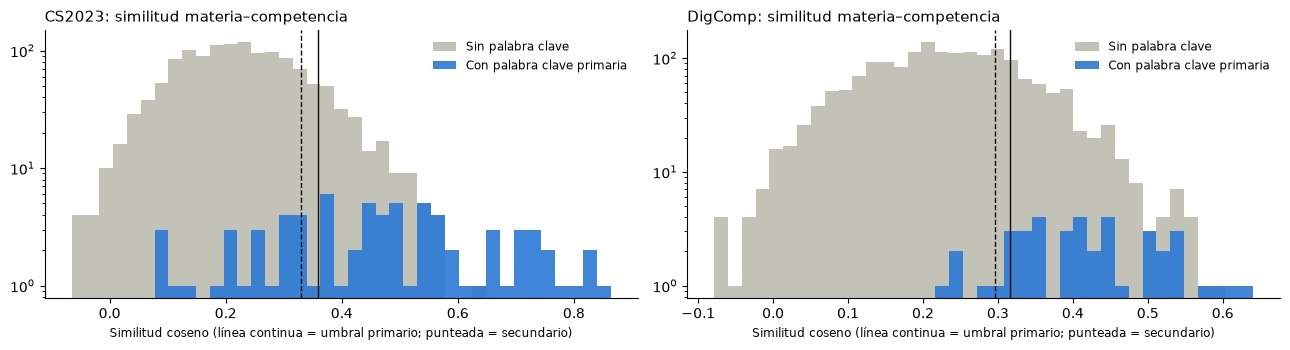

In [51]:
# 4) Calibración de umbrales por marco (Youden sobre las etiquetas de palabra clave primaria)
def calibrar(df):
    pos, neg = df.loc[df["kw"] == 1.0, "sim"], df.loc[df["kw"] == 0.0, "sim"]
    if len(pos) < 5 or len(neg) < 5:
        return 0.50, 0.40
    cands = np.unique(np.quantile(df["sim"], np.linspace(0.50, 0.995, 200)))
    j = [(pos >= t).mean() - (neg >= t).mean() for t in cands]
    prim = float(cands[int(np.argmax(j))])
    sec = float(min(prim - 0.02, (prim + neg.quantile(0.75)) / 2))
    return prim, sec

UMBRALES = {}
if BACKEND != "keywords":
    for marco, df in pares.groupby("marco"):
        UMBRALES[marco] = calibrar(df) if UMBRAL_EMB == "auto" else tuple(UMBRAL_EMB)
    print("Umbrales (primario, secundario):", {k: tuple(round(x, 3) for x in v) for k, v in UMBRALES.items()})

    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
    for ax, (marco, df) in zip(axes, pares.groupby("marco")):
        bins = np.linspace(df["sim"].min(), df["sim"].max(), 40)
        ax.hist(df.loc[df["kw"] == 0, "sim"], bins=bins, color="#c3c2b7", label="Sin palabra clave")
        ax.hist(df.loc[df["kw"] == 1, "sim"], bins=bins, color="#2a78d6", alpha=0.9, label="Con palabra clave primaria")
        for t, ls in zip(UMBRALES[marco], ["-", "--"]):
            ax.axvline(t, color="#0b0b0b", lw=1, ls=ls)
        ax.set_yscale("log"); ax.set_title(f"{marco}: similitud materia–competencia", fontsize=11, loc="left")
        ax.set_xlabel("Similitud coseno (línea continua = umbral primario; punteada = secundario)", fontsize=8.5)
        ax.legend(fontsize=8.5, frameon=False)
        for s in ["top", "right"]: ax.spines[s].set_visible(False)
    plt.tight_layout(); plt.show()

In [52]:
# 5) Relevancia por embedding (top-k por materia y marco) y combinación según MODO_MAPEO
def rel_embedding(df):
    if BACKEND == "keywords":
        return pd.Series(0.0, index=df.index)
    out = pd.Series(0.0, index=df.index)
    for (i, marco), g in df.groupby(["i", "marco"]):
        prim, sec = UMBRALES[marco]
        top = g[g["sim"] >= sec].nlargest(TOPK_EMB, "sim")
        out.loc[top.index] = np.where(top["sim"] >= prim, 1.0, 0.5)
    return out

pares["emb"] = rel_embedding(pares)
if MODO_MAPEO == "keywords":
    pares["relevancia"] = pares["kw"]
elif MODO_MAPEO == "embeddings":
    pares["relevancia"] = pares["emb"]
else:
    pares["relevancia"] = pares[["kw", "emb"]].max(axis=1)
pares["fuente"] = np.select([(pares["kw"] > 0) & (pares["emb"] > 0), pares["kw"] > 0, pares["emb"] > 0],
                            ["ambos", "keyword", "embedding"], default="")

auto = pares[pares["relevancia"] > 0].merge(
    mat[["programa", "codigo", "materia", "capa", "creditos", "nivel"]], left_on="i", right_index=True)
auto = auto[["programa", "codigo", "materia", "capa", "creditos", "marco", "competencia", "nivel",
             "relevancia", "fuente", "kw", "emb", "sim"]]

# 6) Respetar correcciones manuales y guardar por programa
partes = []
for pid in planes:
    a = auto[auto["programa"] == pid]
    ruta = DATOS / "mapeo" / f"{pid}.csv"
    if ruta.exists():
        prev = pd.read_csv(ruta, dtype={"codigo": str, "competencia": str}).fillna({"codigo": ""})
        manual = prev[prev["fuente"] == "manual"]
        if not manual.empty:
            clave = ["materia", "marco", "competencia"]
            a = a.merge(manual[clave], on=clave, how="left", indicator=True)
            a = a[a["_merge"] == "left_only"].drop(columns="_merge")
            a = pd.concat([a, manual], ignore_index=True)
    a.to_csv(ruta, index=False)
    partes.append(a)
mapeo = pd.concat(partes, ignore_index=True)
mapeo["competencia"] = mapeo["competencia"].astype(str)

print(f"Modo: {MODO_MAPEO} · vínculos: {len(mapeo)}")
print(mapeo.pivot_table(index="marco", columns="fuente", values="materia", aggfunc="count", fill_value=0))

Modo: hibrido · vínculos: 455
fuente   ambos  embedding  keyword
marco                             
CS2023      70        101       49
DigComp     36        168       31


In [53]:
# 7) Discrepancias entre métodos: lo primero que deberían revisar los expertos
disc = pares[(pares["kw"] > 0) != (pares["emb"] > 0)].merge(mat[["programa", "materia"]], left_on="i", right_index=True)
disc["solo_por"] = np.where(disc["kw"] > 0, "keyword", "embedding")
disc["nombre_competencia"] = [(CS2023 if m == "CS2023" else DIGCOMP)[c]["nombre"] for m, c in zip(disc["marco"], disc["competencia"])]
disc = disc.sort_values(["solo_por", "sim"], ascending=[True, False])[
    ["programa", "materia", "marco", "competencia", "nombre_competencia", "solo_por", "kw", "emb", "sim"]].round(3)
print(f"Vínculos detectados por un solo método: {len(disc)}")
print("\nMaterias que ahora tienen área CS2023 solo gracias a los embeddings:")
cs_kw = set(pares.loc[(pares["marco"] == "CS2023") & (pares["kw"] > 0), "i"])
cs_emb = set(pares.loc[(pares["marco"] == "CS2023") & (pares["emb"] > 0), "i"])
nuevas = mat.loc[sorted(cs_emb - cs_kw), ["programa", "materia"]]
print(nuevas.to_string(index=False) if len(nuevas) else "  (ninguna)")
disc.head(40)

Vínculos detectados por un solo método: 349

Materias que ahora tienen área CS2023 solo gracias a los embeddings:
 programa                     materia
iit_bs_ai Introduction to Linguistics


,programa,materia,marco,competencia,nombre_competencia,solo_por,kw,emb,sim
1797,iit_bs_ai,Software Engineering I,CS2023,SDF,Fundamentos de desarrollo de software,embedding,0.0,1.0,0.629
968,uade_iacd,CONSULTORÍA EN PROYECTOS DE DATOS E INTELIGENC...,DigComp,1.2,Evaluación de información,embedding,0.0,1.0,0.588
2945,iit_bs_ai,Information Retrieval,DigComp,1.3,Gestión de información y datos,embedding,0.0,1.0,0.576
2854,iit_bs_ai,Computer Organization and Assembly Language Pr...,CS2023,FPL,Lenguajes de programación,embedding,0.0,1.0,0.573
1521,iit_bs_ai,Programming Paradigms and Patterns,CS2023,AL,Algoritmos y fundamentos,embedding,0.0,1.0,0.562
987,uade_iacd,CONSULTORÍA EN PROYECTOS DE DATOS E INTELIGENC...,DigComp,5.4,Necesidades de competencia digital,embedding,0.0,1.0,0.558
493,uade_iacd,ANALÍTICAS DE MARKETING DIGITAL,DigComp,5.4,Necesidades de competencia digital,embedding,0.0,1.0,0.557
40,uade_iacd,"PENSAMIENTO COMPUTACIONAL, ALGORITMIA Y PROGRA...",CS2023,AR,Arquitectura y organización,embedding,0.0,1.0,0.557
625,uade_iacd,ANALÍTICAS PARA SISTEMAS DE INFORMACIÓN GEOGRÁ...,DigComp,1.1,Búsqueda y filtrado de información,embedding,0.0,1.0,0.550
484,uade_iacd,ANALÍTICAS DE MARKETING DIGITAL,DigComp,3.3,Derechos de autor y licencias,embedding,0.0,1.0,0.549


### 6.1 Validación contra jueces expertos (kappa de Cohen)

El mapeo automático se valida contra una codificación experta **ciega**, sin ver qué decidió el algoritmo:
1. En la primera corrida se genera `datos/validacion_plantilla.csv` con una muestra de materias × áreas CS2023 y la columna `experto` vacía.
2. Cada juez completa `experto` con 1 o 0 y guarda el archivo como `datos/validacion_expertos.csv`.
3. Al volver a correr, se calcula el kappa de cada método (palabras clave, embeddings, híbrido) contra el experto. El umbral de aceptación es κ ≥ 0,70.

Si hay dos jueces, conviene calcular primero el kappa entre ellos con sus dos columnas.

In [54]:
def kappa(a, b):
    a, b = np.asarray(a, int), np.asarray(b, int)
    po = (a == b).mean()
    pe = a.mean() * b.mean() + (1 - a.mean()) * (1 - b.mean())
    return (po - pe) / (1 - pe) if pe < 1 else np.nan

ruta_val, ruta_pl = DATOS / "validacion_expertos.csv", DATOS / "validacion_plantilla.csv"
if ruta_val.exists():
    val = pd.read_csv(ruta_val, dtype={"competencia": str}).dropna(subset=["experto"])
    ref = pares[pares["marco"] == "CS2023"].merge(mat[["programa", "materia"]], left_on="i", right_index=True)
    val = val.merge(ref[["programa", "materia", "competencia", "kw", "emb"]], on=["programa", "materia", "competencia"], how="left").fillna(0)
    res = {"Palabras clave": kappa(val["experto"], val["kw"] > 0),
           "Embeddings": kappa(val["experto"], val["emb"] > 0),
           "Híbrido": kappa(val["experto"], (val["kw"] > 0) | (val["emb"] > 0))}
    display(pd.Series(res, name="kappa vs. experto").round(3).to_frame())
elif not ruta_pl.exists():
    rng = np.random.default_rng(SEMILLA_ALEATORIA)
    base = mat[mat["capa"].isin(["core", "major_elective"])]
    muestra = pd.concat([g.sample(min(len(g), 12), random_state=SEMILLA_ALEATORIA) for _, g in base.groupby("programa")])
    plantilla = muestra[["programa", "codigo", "materia"]].merge(
        pd.DataFrame({"competencia": KA, "area": [CS2023[k]["nombre"] for k in KA]}), how="cross")
    plantilla["experto"] = ""
    plantilla.to_csv(ruta_pl, index=False)
    print(f"Plantilla ciega creada: {ruta_pl} ({len(muestra)} materias × 17 áreas). Completala y guardala como {ruta_val.name}.")
else:
    print(f"Pendiente: completar {ruta_pl} y guardarlo como {ruta_val}.")

Pendiente: completar datos\validacion_plantilla.csv y guardarlo como datos\validacion_expertos.csv.


## 7. Cobertura garantizada y ofrecida

Para el programa *p* y la competencia *c*:

$$C_{p,c} = \sum_{m \in p} \text{créditos}_m \cdot \text{nivel}_{m,c} \cdot \text{relevancia}_{m,c}$$

- **Garantizada:** solo materias `core` (y `gen_ed` para DigComp).
- **Ofrecida:** suma también las `major_elective`. Es una cota superior: supone que el estudiante podría cursar todas las electivas nombradas.

Además se calcula el **nivel máximo** alcanzado por área, que alimenta la profundidad, y el **CCI** (áreas con cobertura > 0 / total).

In [55]:
CAPAS = {"garantizada": {"core", "gen_ed"}, "ofrecida": {"core", "gen_ed", "major_elective"}}
PROGS = [FOCAL] + BENCH

def matriz(marco, modo, valor="cobertura"):
    m = mapeo[(mapeo["marco"] == marco) & (mapeo["capa"].isin(CAPAS[modo]))].copy()
    cols = KA if marco == "CS2023" else DC
    if valor == "cobertura":
        m["v"] = m["creditos"] * m["nivel"] * m["relevancia"]
        t = m.pivot_table(index="programa", columns="competencia", values="v", aggfunc="sum")
    else:  # nivel máximo, solo vínculos con relevancia plena o parcial
        t = m.pivot_table(index="programa", columns="competencia", values="nivel", aggfunc="max")
    return t.reindex(index=PROGS, columns=cols).fillna(0)

COB = {(mc, md_): matriz(mc, md_) for mc in ["CS2023","DigComp"] for md_ in CAPAS}
NIV = {(mc, md_): matriz(mc, md_, "nivel") for mc in ["CS2023","DigComp"] for md_ in CAPAS}

def cci(marco, modo, subconjunto=None):
    M = NIV[(marco, modo)]
    cols = subconjunto if subconjunto is not None else M.columns
    return (M[cols] > 0).mean(axis=1) * 100

areas_perfil = list(pesos(PERFIL)[lambda s: s > 0].index)
tabla_cci = pd.DataFrame({
    "CCI garantizado (17)": cci("CS2023","garantizada"),
    "CCI ofrecido (17)":    cci("CS2023","ofrecida"),
    f"CCI garantizado ({PERFIL})": cci("CS2023","garantizada", areas_perfil),
    f"CCI ofrecido ({PERFIL})":    cci("CS2023","ofrecida", areas_perfil),
    "Profundidad media garantizada (0-4)": NIV[("CS2023","garantizada")].mean(axis=1),
    "Cobertura DigComp garantizada (%)":   cci("DigComp","garantizada"),
}).round(1)
tabla_cci["Flexibilidad (pp)"] = tabla_cci["CCI ofrecido (17)"] - tabla_cci["CCI garantizado (17)"]
tabla_cci.rename(index=NOMBRE)

,CCI garantizado (17),CCI ofrecido (17),CCI garantizado (ia_datos),CCI ofrecido (ia_datos),Profundidad media garantizada (0-4),Cobertura DigComp garantizada (%),Flexibilidad (pp)
programa,,,,,,,
UADE – Lic. en IA y Ciencia de Datos,88.2,88.2,88.9,88.9,3.3,81.0,0.0
Illinois Tech – BS Artificial Intelligence,70.6,94.1,88.9,100.0,2.2,76.2,23.5


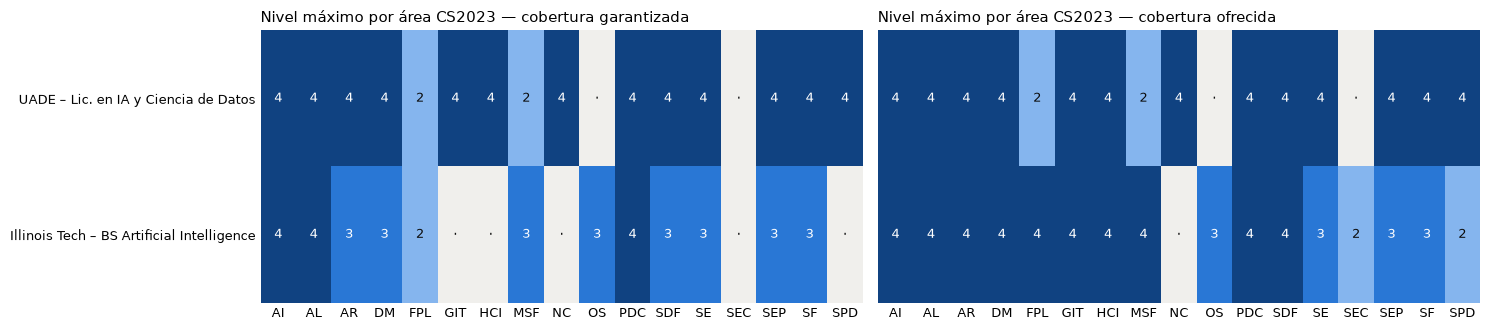

In [56]:
# Mapa de calor del nivel máximo por área (0 = sin cobertura). Rampa secuencial de un solo tono.
RAMPA = LinearSegmentedColormap.from_list("azul", ["#f0efec", "#cde2fb", "#86b6ef", "#2a78d6", "#104281"])

fig, axes = plt.subplots(1, 2, figsize=(15, 0.6 * len(PROGS) + 2.2), sharey=True)
for ax, modo in zip(axes, ["garantizada", "ofrecida"]):
    M = NIV[("CS2023", modo)]
    ax.imshow(M.values, cmap=RAMPA, vmin=0, vmax=4, aspect="auto")
    ax.set_xticks(range(len(KA)), KA, fontsize=9)
    ax.set_yticks(range(len(PROGS)), [NOMBRE[p] for p in PROGS], fontsize=9)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = int(M.iat[i, j])
            ax.text(j, i, v if v else "·", ha="center", va="center", fontsize=9,
                    color="#ffffff" if v >= 3 else "#0b0b0b")
    ax.set_title(f"Nivel máximo por área CS2023 — cobertura {modo}", fontsize=11, loc="left")
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(length=0)
plt.tight_layout(); plt.show()

## 8. Brecha por área, DSGI y subíndices

$$B_c = \operatorname{mediana}_{p \in \text{benchmark}}(C_{p,c}) \qquad G_c = \frac{B_c - C_{\text{UADE},c}}{B_c} \qquad \text{DSGI} = \sum_c w_c \cdot \max(0, G_c)$$

- Si $B_c = 0$, la brecha no se define: el área se reporta como **ventaja diferencial** cuando UADE la cubre.
- Un $G_c < 0$ indica que UADE supera al benchmark (**ventaja**).
- Los pesos se renormalizan sobre las áreas con $B_c > 0$.

In [57]:
def brechas(marco, modo, benchmark=None):
    benchmark = benchmark or BENCH
    M = COB[(marco, modo)]
    B = M.loc[benchmark].median(axis=0)
    U = M.loc[FOCAL]
    G = pd.Series(np.where(B > 0, (B - U) / B, np.nan), index=M.columns)
    return pd.DataFrame({"UADE": U, "Benchmark (mediana)": B, "G": G})

def dsgi(marco, modo, w=None, benchmark=None):
    g = brechas(marco, modo, benchmark)
    cols = g.index
    w = (w if w is not None else pd.Series(1.0, index=cols)).reindex(cols).fillna(0)
    ok = g["G"].notna() & (w > 0)
    if not ok.any(): return np.nan
    w = w[ok] / w[ok].sum()
    return float((w * g.loc[ok, "G"].clip(lower=0)).sum())

def ic_bootstrap(marco, modo, w=None, n=N_BOOTSTRAP):
    rng = np.random.default_rng(SEMILLA_ALEATORIA)
    vals = [dsgi(marco, modo, w, list(rng.choice(BENCH, size=len(BENCH), replace=True))) for _ in range(n)]
    return np.nanpercentile(vals, [2.5, 97.5])

filas = []
for modo in CAPAS:
    for etiqueta, marco, w in [("Técnico – 17 áreas", "CS2023", pesos("cs_completo")),
                               (f"Técnico – perfil {PERFIL}", "CS2023", pesos(PERFIL)),
                               ("Transversal – DigComp 3.0", "DigComp", None)]:
        v = dsgi(marco, modo, w); lo, hi = ic_bootstrap(marco, modo, w)
        filas.append(dict(benchmark=modo, indice=etiqueta, DSGI=round(v, 3), IC95=f"[{lo:.2f}, {hi:.2f}]"))
    g_ai = brechas("CS2023", modo).loc["AI", "G"]
    filas.append(dict(benchmark=modo, indice="IA (área AI de CS2023)", DSGI=round(max(0, g_ai), 3) if pd.notna(g_ai) else np.nan, IC95="—"))
tabla_dsgi = pd.DataFrame(filas)
if len(BENCH) < 8:
    print(f"Aviso: solo {len(BENCH)} programas de benchmark. El IC por bootstrap no es informativo con menos de ~8.")
tabla_dsgi

Aviso: solo 1 programas de benchmark. El IC por bootstrap no es informativo con menos de ~8.


,benchmark,indice,DSGI,IC95
0,garantizada,Técnico – 17 áreas,0.258,"[0.26, 0.26]"
1,garantizada,Técnico – perfil ia_datos,0.168,"[0.17, 0.17]"
2,garantizada,Transversal – DigComp 3.0,0.305,"[0.30, 0.30]"
3,garantizada,IA (área AI de CS2023),0.000,—
4,ofrecida,Técnico – 17 áreas,0.402,"[0.40, 0.40]"
5,ofrecida,Técnico – perfil ia_datos,0.492,"[0.49, 0.49]"
6,ofrecida,Transversal – DigComp 3.0,0.400,"[0.40, 0.40]"
7,ofrecida,IA (área AI de CS2023),0.152,—


In [58]:
# Detalle por área para el perfil activo y posición de UADE dentro del benchmark
def detalle(modo):
    g = brechas("CS2023", modo)
    M = COB[("CS2023", modo)].loc[BENCH]
    g["Percentil UADE"] = [(M[c] <= g.at[c, "UADE"]).mean() * 100 for c in g.index]
    g["z-score"] = [(g.at[c, "UADE"] - M[c].mean()) / M[c].std(ddof=0) if M[c].std(ddof=0) > 0 else np.nan for c in g.index]
    g["Peso perfil"] = pesos(PERFIL)
    g["Lectura"] = np.select(
        [g["G"].isna() & (g["UADE"] > 0), g["G"].isna(), g["G"] > 0.5, g["G"] > 0, g["G"] <= 0],
        ["Ventaja diferencial (el benchmark no la cubre)", "Sin cobertura en ningún programa",
         "Brecha alta", "Brecha moderada", "Ventaja"], default="")
    g.insert(0, "Área", [CS2023[c]["nombre"] for c in g.index])
    return g.round(2)

DET = {m: detalle(m) for m in CAPAS}
DET["garantizada"]

,Área,UADE,Benchmark (mediana),G,Percentil UADE,z-score,Peso perfil,Lectura
competencia,,,,,,,,
AI,Inteligencia artificial,159.0,54.0,-1.94,100.0,NaN,0.11,Ventaja
AL,Algoritmos y fundamentos,45.0,72.0,0.38,0.0,NaN,0.11,Brecha moderada
AR,Arquitectura y organización,90.0,56.0,-0.61,100.0,NaN,0.00,Ventaja
DM,Gestión de datos,46.5,24.0,-0.94,100.0,NaN,0.11,Ventaja
FPL,Lenguajes de programación,3.0,12.0,0.75,0.0,NaN,0.00,Brecha alta
GIT,Gráficos y técnicas interactivas,42.0,0.0,NaN,100.0,NaN,0.00,Ventaja diferencial (el benchmark no la cubre)
HCI,Interacción humano-computadora,27.0,0.0,NaN,100.0,NaN,0.00,Ventaja diferencial (el benchmark no la cubre)
MSF,Fundamentos matemáticos y estadísticos,21.0,49.0,0.57,0.0,NaN,0.11,Brecha alta
NC,Redes y comunicación,18.0,0.0,NaN,100.0,NaN,0.00,Ventaja diferencial (el benchmark no la cubre)


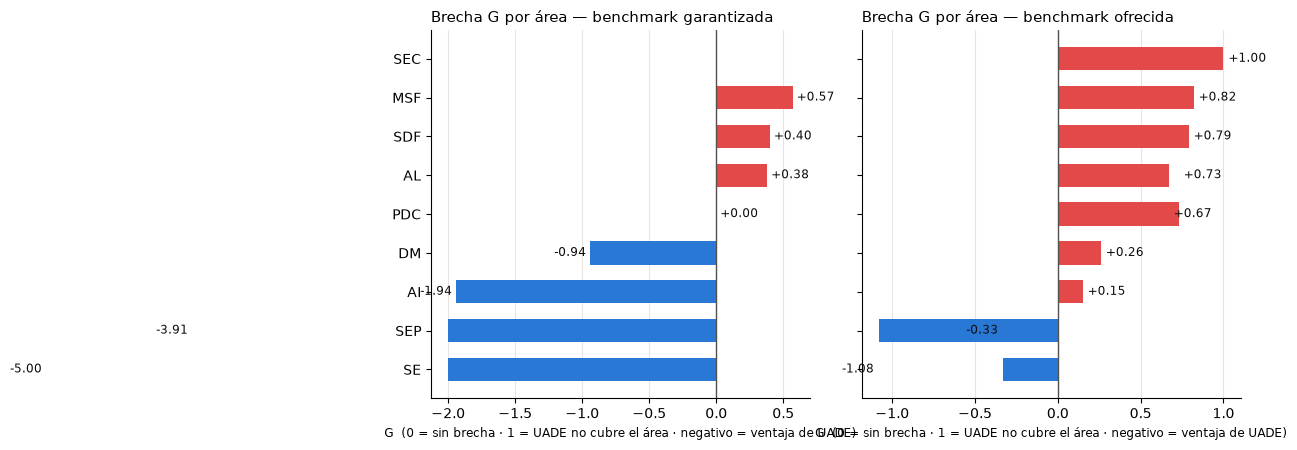

In [59]:
# Brecha por área (perfil activo): rojo = déficit de UADE, azul = ventaja. Una sola escala, cero en el centro.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, modo in zip(axes, CAPAS):
    d = DET[modo].loc[areas_perfil].dropna(subset=["G"]).sort_values("G")
    colores = ["#e34948" if v > 0 else "#2a78d6" for v in d["G"]]
    ax.barh(d.index, d["G"].clip(-2, 1), color=colores, height=0.6)
    ax.axvline(0, color="#52514e", lw=1)
    for y, v in enumerate(d["G"]):
        ax.text(v + (0.03 if v >= 0 else -0.03), y, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right",
                fontsize=8.5, color="#0b0b0b")
    ax.set_title(f"Brecha G por área — benchmark {modo}", fontsize=11, loc="left")
    ax.set_xlabel("G  (0 = sin brecha · 1 = UADE no cubre el área · negativo = ventaja de UADE)", fontsize=8.5)
    ax.grid(axis="x", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

## 9. Redes complejas: espacio de competencias y priorización

1. **RCA** (ventaja comparativa revelada) de cada programa en cada área. El programa "desarrolla" el área si RCA ≥ 1.
2. **Proximidad** entre áreas: $\phi_{c,c'} = \min\{P(c \mid c'),\ P(c' \mid c)\}$.
3. **Densidad** de cada área para UADE: $\omega_c = \sum_{c'} \phi_{c,c'} x_{\text{UADE},c'} / \sum_{c'} \phi_{c,c'}$.
4. **Centralidad** de cada área en la red de proximidad: grado ponderado normalizado e intermediación.
5. **Mapa de priorización** de las áreas con brecha: centralidad × densidad, con cortes en la mediana.

> Con pocos programas, la proximidad es inestable. El análisis de redes tiene sentido con el cluster completo (idealmente 8 o más programas). Por ahora la red incluye a UADE para que no quede vacía.

In [60]:
MODO_RED = "ofrecida"
M = COB[("CS2023", MODO_RED)].copy()
M = M.loc[:, M.sum(axis=0) > 0]

tot = M.values.sum()
rca = (M.div(M.sum(axis=1), axis=0)) / (M.sum(axis=0) / tot)
X = (rca >= 1).astype(int)

ubiq = X.sum(axis=0)
co = X.T @ X
phi = pd.DataFrame(0.0, index=X.columns, columns=X.columns)
for a in X.columns:
    for b in X.columns:
        if a != b and ubiq[a] > 0 and ubiq[b] > 0:
            phi.at[a, b] = min(co.at[a, b] / ubiq[b], co.at[a, b] / ubiq[a])

xu = X.loc[FOCAL]
densidad = (phi @ xu) / phi.sum(axis=1).replace(0, np.nan)

Gr = nx.Graph()
Gr.add_nodes_from(phi.index)
for a in phi.index:
    for b in phi.columns:
        if a < b and phi.at[a, b] > 0:
            Gr.add_edge(a, b, weight=phi.at[a, b], distance=1 - phi.at[a, b] + 1e-6)
grado = pd.Series(dict(Gr.degree(weight="weight")))
grado = grado / grado.max() if grado.max() > 0 else grado
interm = pd.Series(nx.betweenness_centrality(Gr, weight="distance"))

red = pd.DataFrame({"Área": [CS2023[c]["nombre"] for c in phi.index],
                    "UADE la desarrolla (RCA≥1)": xu.reindex(phi.index).astype(bool),
                    "Densidad": densidad.round(2), "Centralidad (grado)": grado.round(2),
                    "Intermediación": interm.round(2)})
red["G"] = DET[MODO_RED]["G"].reindex(red.index)
con_brecha = red[(red["G"] > 0) & (pesos(PERFIL).reindex(red.index) > 0)].copy()
cx, cy = red["Densidad"].median(), red["Centralidad (grado)"].median()
def cuadrante(r):
    alta_c, cerca = r["Centralidad (grado)"] >= cy, r["Densidad"] >= cx
    return {(True, True): "Crítica y cercana (prioridad 1)", (True, False): "Crítica y lejana",
            (False, True): "Menor y cercana", (False, False): "Menor y lejana"}[(alta_c, cerca)]
con_brecha["Prioridad"] = con_brecha.apply(cuadrante, axis=1)
print("Brechas del perfil", PERFIL, "— priorización:")
con_brecha.sort_values(["Prioridad", "G"], ascending=[True, False])

Brechas del perfil ia_datos — priorización:


,Área,UADE la desarrolla (RCA≥1),Densidad,Centralidad (grado),Intermediación,G,Prioridad
DM,Gestión de datos,True,1.0,1.00,0.0,0.26,Crítica y cercana (prioridad 1)
AI,Inteligencia artificial,True,1.0,1.00,0.0,0.15,Crítica y cercana (prioridad 1)
SEC,Seguridad,False,0.0,0.67,0.0,1.00,Menor y lejana
MSF,Fundamentos matemáticos y estadísticos,False,0.0,0.67,0.0,0.82,Menor y lejana
SDF,Fundamentos de desarrollo de software,False,0.0,0.67,0.0,0.79,Menor y lejana
PDC,Computación paralela y distribuida,False,0.0,0.67,0.0,0.73,Menor y lejana
AL,Algoritmos y fundamentos,False,0.0,0.67,0.0,0.67,Menor y lejana


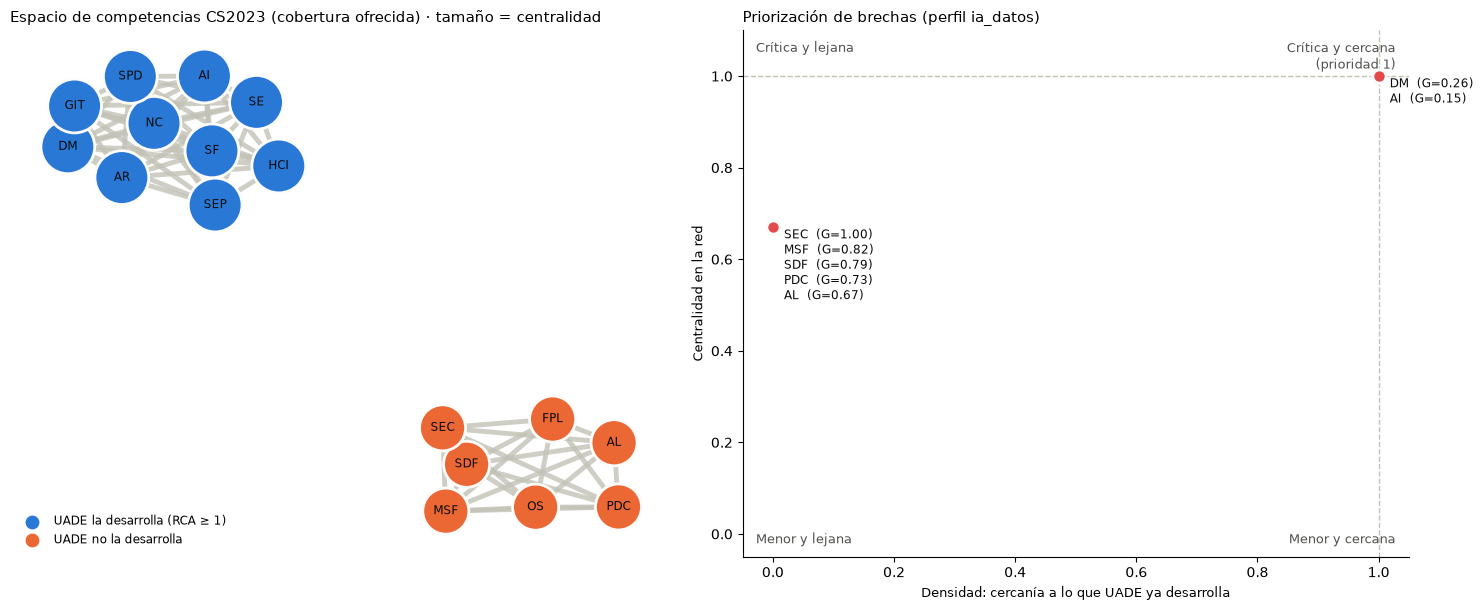

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))

# (a) Red de proximidad entre áreas
ax = axes[0]
pos = nx.spring_layout(Gr, weight="weight", seed=SEMILLA_ALEATORIA, k=0.9)
anchos = [0.5 + 3 * d["weight"] for *_, d in Gr.edges(data=True)]
nx.draw_networkx_edges(Gr, pos, ax=ax, width=anchos, edge_color="#c3c2b7", alpha=0.8)
col = ["#2a78d6" if xu.get(n, 0) else "#eb6834" for n in Gr.nodes]
tam = [300 + 1200 * grado.get(n, 0) for n in Gr.nodes]
nx.draw_networkx_nodes(Gr, pos, ax=ax, node_color=col, node_size=tam, edgecolors="#fcfcfb", linewidths=2)
nx.draw_networkx_labels(Gr, pos, ax=ax, font_size=8.5, font_color="#0b0b0b")
ax.scatter([], [], c="#2a78d6", s=80, label="UADE la desarrolla (RCA ≥ 1)")
ax.scatter([], [], c="#eb6834", s=80, label="UADE no la desarrolla")
ax.legend(loc="lower left", fontsize=8.5, frameon=False)
ax.set_title(f"Espacio de competencias CS2023 (cobertura {MODO_RED}) · tamaño = centralidad", fontsize=11, loc="left")
ax.axis("off")

# (b) Mapa de priorización de brechas
ax = axes[1]
ax.axvline(cx, color="#c3c2b7", lw=1, ls="--"); ax.axhline(cy, color="#c3c2b7", lw=1, ls="--")
ax.scatter(con_brecha["Densidad"], con_brecha["Centralidad (grado)"], s=90, color="#e34948",
           edgecolors="#fcfcfb", linewidths=2, zorder=3)
# Áreas con la misma posición se rotulan juntas (frecuente con pocos programas)
for (xd, yc), grupo in con_brecha.groupby([con_brecha["Densidad"].round(2), con_brecha["Centralidad (grado)"].round(2)]):
    etiqueta = "\n".join(f"{c}  (G={r['G']:.2f})" for c, r in grupo.sort_values("G", ascending=False).iterrows())
    ax.annotate(etiqueta, (xd, yc), xytext=(8, 0), textcoords="offset points", fontsize=8.5,
                color="#0b0b0b", va="top" if len(grupo) > 1 else "center")
ax.text(0.98, 0.98, "Crítica y cercana\n(prioridad 1)", transform=ax.transAxes, ha="right", va="top", fontsize=9, color="#52514e")
ax.text(0.02, 0.98, "Crítica y lejana", transform=ax.transAxes, ha="left", va="top", fontsize=9, color="#52514e")
ax.text(0.98, 0.02, "Menor y cercana", transform=ax.transAxes, ha="right", va="bottom", fontsize=9, color="#52514e")
ax.text(0.02, 0.02, "Menor y lejana", transform=ax.transAxes, ha="left", va="bottom", fontsize=9, color="#52514e")
ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.1)
ax.set_xlabel("Densidad: cercanía a lo que UADE ya desarrolla", fontsize=9)
ax.set_ylabel("Centralidad en la red", fontsize=9)
ax.set_title(f"Priorización de brechas (perfil {PERFIL})", fontsize=11, loc="left")
for s in ["top", "right"]: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

## 10. Brecha percibida (opcional)

Si ya tienen resultados de la encuesta, cargá `datos/encuesta_vs_ecar.csv` con las columnas `item, pct_uade, n_uade, pct_ecar`. Los porcentajes van de 0 a 100 y se usa la misma agregación que publica ECAR. Para cada ítem se calcula la diferencia con un IC del 95%, tomando el valor de ECAR como fijo porque sus microdatos no son públicos.

In [62]:
ruta_enc = DATOS / "encuesta_vs_ecar.csv"
if ruta_enc.exists():
    enc = pd.read_csv(ruta_enc)
    p = enc["pct_uade"] / 100
    se = np.sqrt(p * (1 - p) / enc["n_uade"])
    enc["dif_pp"] = enc["pct_uade"] - enc["pct_ecar"]
    enc["IC95_pp"] = [f"[{(d - 196*s):.1f}, {(d + 196*s):.1f}]" for d, s in zip(enc["dif_pp"], se)]
    display(enc)
else:
    print("Sin datos de encuesta todavía (", ruta_enc, ").")

Sin datos de encuesta todavía ( datos\encuesta_vs_ecar.csv ).


## 11. Exportar resultados

In [63]:
salida = DATOS / "resultados" / "simulacion_brecha_embeddings.xlsx"
with pd.ExcelWriter(salida) as xl:
    tabla_cci.rename(index=NOMBRE).to_excel(xl, sheet_name="CCI y profundidad")
    tabla_dsgi.to_excel(xl, sheet_name="DSGI", index=False)
    for m in CAPAS:
        DET[m].to_excel(xl, sheet_name=f"Brecha por area ({m[:5]})")
        NIV[("CS2023", m)].rename(index=NOMBRE).to_excel(xl, sheet_name=f"Nivel CS2023 ({m[:5]})")
        COB[("DigComp", m)].rename(index=NOMBRE).to_excel(xl, sheet_name=f"Cobertura DigComp ({m[:5]})")
    red.to_excel(xl, sheet_name="Red de competencias")
    con_brecha.to_excel(xl, sheet_name="Priorizacion")
    mapeo.to_excel(xl, sheet_name="Mapeo materia-competencia", index=False)
    disc.to_excel(xl, sheet_name="Discrepancias kw vs emb", index=False)
print("Guardado en", salida.resolve())

Guardado en C:\Users\JPy\Documents\UADE\A26T13 Skill Gap\datos\resultados\simulacion_brecha_embeddings.xlsx


## Notas y límites

- **Los embeddings sobre nombres de materias son limitados.** Con los contenidos mínimos cargados en `contenidos` la precisión sube bastante. Los umbrales automáticos se calibran contra las palabras clave, así que conviene revisarlos con la validación experta (6.1).
- **El mapeo automático es un primer pase.** Valídenlo con una doble codificación experta (kappa ≥ 0,70) antes de usar los resultados.
- **Créditos de UADE.** Mientras no se cargue la carga horaria real, cada materia de UADE vale `CREDITOS_DEFAULT`. Eso afecta la magnitud de *C*, no el CCI.
- **La cobertura ofrecida es una cota superior.** Supone que se pueden cursar todas las electivas nombradas.
- **La red necesita el cluster completo.** Con 2 o 3 programas, la proximidad y la densidad solo sirven para probar el código.
- **Faltan los estándares de Ciencia de Datos y Bioinformática.** Por ahora la dimensión técnica usa CS2023 con perfiles de pesos. Cuando se definan, se agregan como un tercer marco en la sección 2.